# CISC7204 Assignment 01 - Module 03 - Lab02 Exploratory Data Analysis - Laptop Pricing


In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod1.csv"
df = pd.read_csv(DATA_URL)
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
pd.set_option("display.max_columns", None)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (238, 12)


  Manufacturer  Category     Screen  GPU  OS  CPU_core  Screen_Size_cm  \
0         Acer         4  IPS Panel    2   1         5          35.560   
1         Dell         3    Full HD    1   1         3          39.624   
2         Dell         3    Full HD    1   1         7          39.624   
3         Dell         4  IPS Panel    2   1         5          33.782   
4           HP         4    Full HD    2   1         7          39.624   

   CPU_frequency  RAM_GB  Storage_GB_SSD  Weight_kg  Price  
0            1.6       8             256       1.60    978  
1            2.0       4             256       2.20    634  
2            2.7       8             256       2.20    946  
3            1.6       8             128       1.22   1244  
4            1.8       8             256       1.91    837  

## Prepare A Clean Laptop Dataset

In [2]:
laptop_df = df.copy()

laptop_df["Screen_Size_cm"] = pd.to_numeric(laptop_df["Screen_Size_cm"], errors="coerce")
laptop_df["Weight_kg"] = pd.to_numeric(laptop_df["Weight_kg"], errors="coerce")

laptop_df["Weight_kg"].fillna(laptop_df["Weight_kg"].mean(), inplace=True)
laptop_df["Screen_Size_cm"].fillna(laptop_df["Screen_Size_cm"].mode()[0], inplace=True)

laptop_df["Screen_Size_inch"] = laptop_df["Screen_Size_cm"] / 2.54
laptop_df["Weight_pounds"] = laptop_df["Weight_kg"] * 2.205
laptop_df["CPU_frequency"] = laptop_df["CPU_frequency"] / laptop_df["CPU_frequency"].max()

bins = np.linspace(laptop_df["Price"].min(), laptop_df["Price"].max(), 4)
labels = ["Low", "Medium", "High"]
laptop_df["Price-binned"] = pd.cut(laptop_df["Price"], bins=bins, labels=labels, include_lowest=True)

screen_dummies = pd.get_dummies(laptop_df["Screen"], prefix="Screen")
laptop_df = pd.concat([laptop_df.drop(columns=["Screen"]), screen_dummies], axis=1)

print("Missing values after cleaning:")
print(laptop_df.isna().sum())
laptop_df.head()

Missing values after cleaning:
Manufacturer        0
Category            0
GPU                 0
OS                  0
CPU_core            0
Screen_Size_cm      0
CPU_frequency       0
RAM_GB              0
Storage_GB_SSD      0
Weight_kg           0
Price               0
Screen_Size_inch    0
Weight_pounds       0
Price-binned        0
Screen_Full HD      0
Screen_IPS Panel    0
dtype: int64


  Manufacturer  Category  GPU  OS  CPU_core  Screen_Size_cm  CPU_frequency  \
0         Acer         4    2   1         5          35.560       0.551724   
1         Dell         3    1   1         3          39.624       0.689655   
2         Dell         3    1   1         7          39.624       0.931034   
3         Dell         4    2   1         5          33.782       0.551724   
4           HP         4    2   1         7          39.624       0.620690   

   RAM_GB  Storage_GB_SSD  Weight_kg  Price  Screen_Size_inch  Weight_pounds  \
0       8             256       1.60    978              14.0        3.52800   
1       4             256       2.20    634              15.6        4.85100   
2       8             256       2.20    946              15.6        4.85100   
3       8             128       1.22   1244              13.3        2.69010   
4       8             256       1.91    837              15.6        4.21155   

  Price-binned  Screen_Full HD  Screen_IPS Panel  

## Task 1: Distribution Of Laptop Prices

Price skewness: 1.274


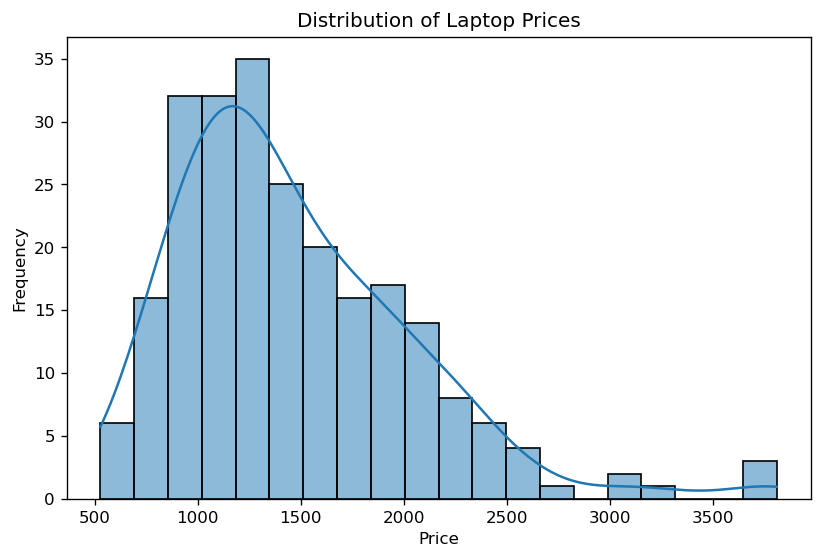

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(laptop_df["Price"], kde=True, bins=20)
plt.title("Distribution of Laptop Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

print("Price skewness:", round(laptop_df["Price"].skew(), 3))

## Task 2: Price By Manufacturer

Manufacturer
Razer      3301.000000
Samsung    2107.400000
Huawei     1714.000000
Toshiba    1703.882353
Dell       1495.084507
Lenovo     1493.096154
MSI        1452.750000
HP         1399.285714
Asus       1327.111111
Xiaomi     1188.000000
Acer       1067.157895
Name: Price, dtype: float64


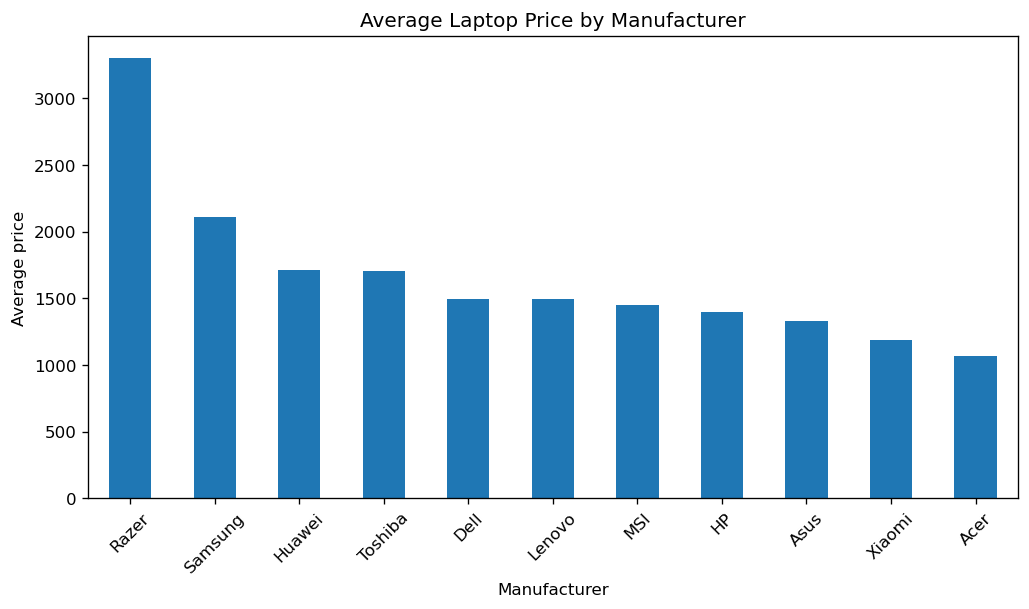

In [4]:
manufacturer_price = laptop_df.groupby("Manufacturer")["Price"].mean().sort_values(ascending=False)
print(manufacturer_price)

plt.figure(figsize=(10, 5))
manufacturer_price.plot(kind="bar")
plt.title("Average Laptop Price by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Average price")
plt.xticks(rotation=45)
plt.show()

## Task 3: Relationship Between Numeric Variables And Price

Price               1.000000
RAM_GB              0.549297
CPU_core            0.459398
CPU_frequency       0.366666
GPU                 0.288298
Category            0.286243
Storage_GB_SSD      0.243421
Weight_pounds      -0.050312
Screen_Size_inch   -0.110644
OS                 -0.221730
Name: Price, dtype: float64


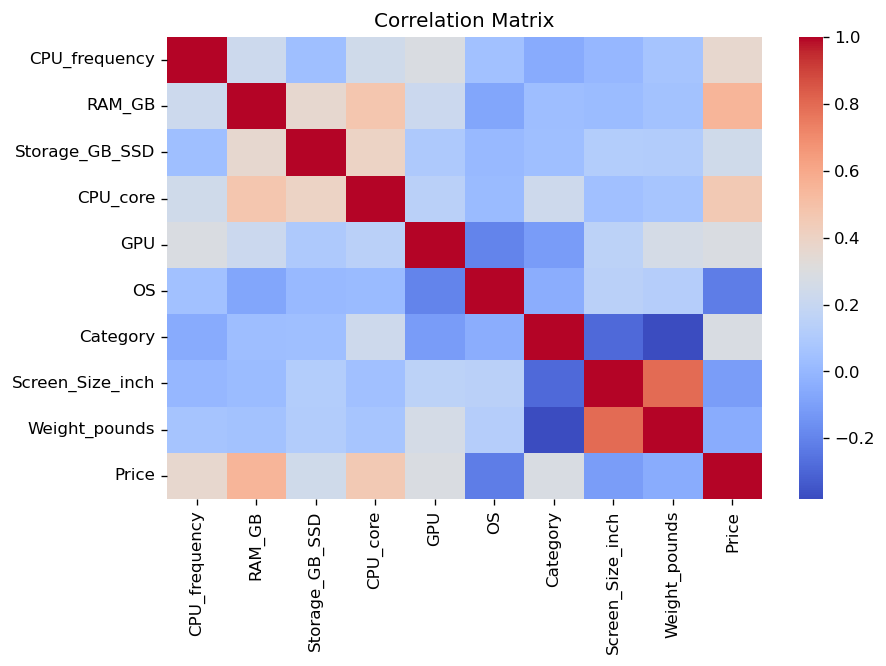

In [5]:
numeric_features = ["CPU_frequency", "RAM_GB", "Storage_GB_SSD", "CPU_core", "GPU", "OS", "Category", "Screen_Size_inch", "Weight_pounds"]

correlations = laptop_df[numeric_features + ["Price"]].corr()["Price"].sort_values(ascending=False)
print(correlations)

plt.figure(figsize=(8, 5))
sns.heatmap(laptop_df[numeric_features + ["Price"]].corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Matrix")
plt.show()

## Task 4: Scatterplots For Key Predictors

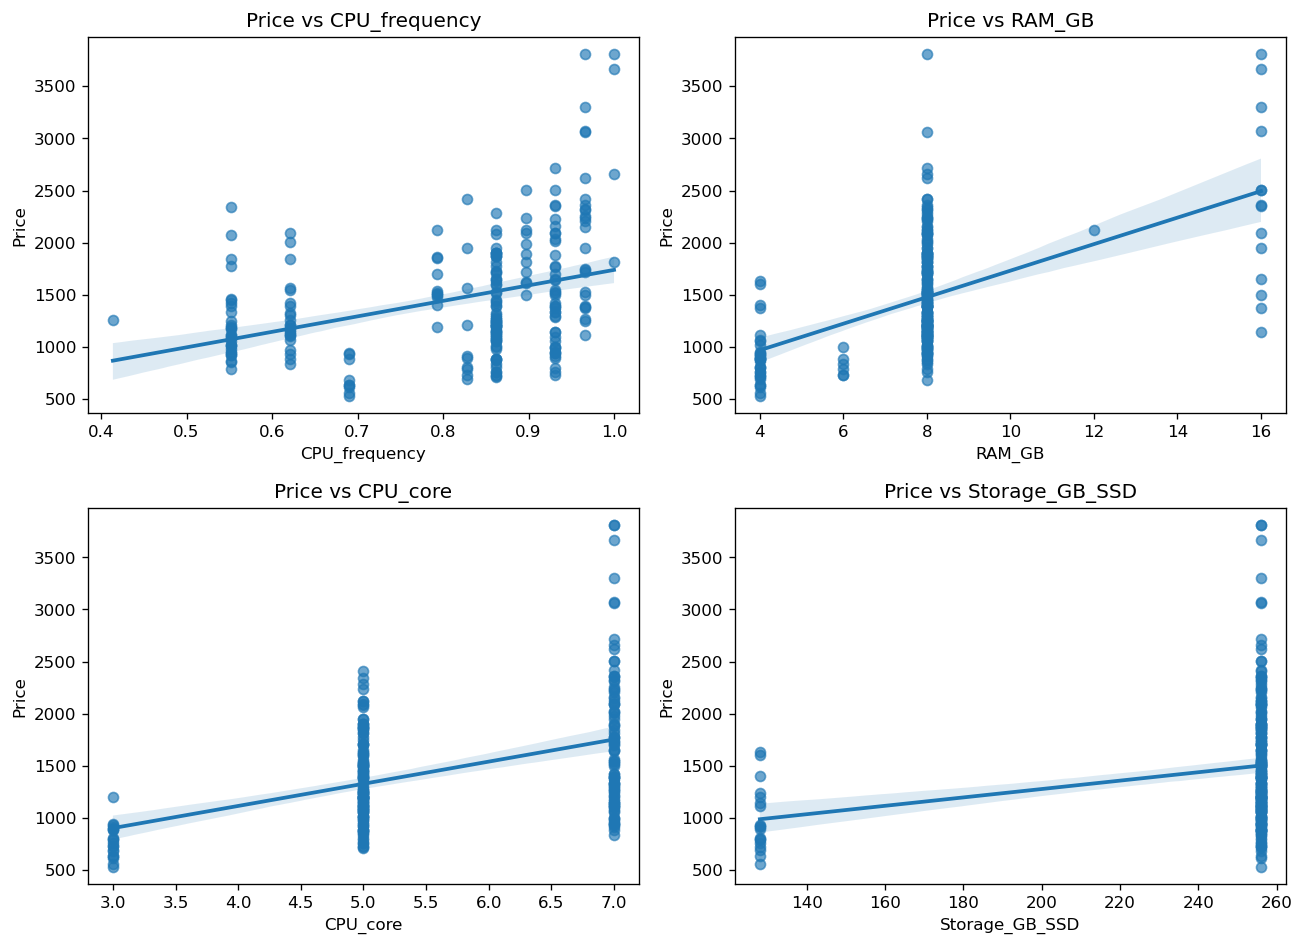

In [6]:
key_features = ["CPU_frequency", "RAM_GB", "CPU_core", "Storage_GB_SSD"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for axis, feature in zip(axes.ravel(), key_features):
    sns.regplot(data=laptop_df, x=feature, y="Price", ax=axis, scatter_kws={"alpha": 0.65})
    axis.set_title(f"Price vs {feature}")

plt.tight_layout()
plt.show()

## Task 5: ANOVA By Manufacturer

In [7]:
from scipy import stats

groups = [group["Price"].values for _, group in laptop_df.groupby("Manufacturer") if len(group) > 1]
f_stat, p_value = stats.f_oneway(*groups)

print("ANOVA F-statistic:", round(f_stat, 4))
print("ANOVA p-value:", p_value)
if p_value < 0.05:
    print("Conclusion: Average prices differ significantly across manufacturers.")
else:
    print("Conclusion: No statistically significant average price difference was detected.")

ANOVA F-statistic: 3.1813
ANOVA p-value: 0.003127251528195749
Conclusion: Average prices differ significantly across manufacturers.
